In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
#Load the cleaned 100K dataset

df = pd.read_csv("../data/processed/final_dataset_100k.csv")

print("Shape:", df.shape)
df.head()

Shape: (100000, 22)


,job_level,age,years_at_company,monthly_income,overtime,job_satisfaction,performance_rating,distance_from_home_km,years_since_promotion,attrition,...,department_Finance,department_Human Resources,department_Marketing,department_Operations,department_Research,department_Sales,work_mode_Hybrid,work_mode_Onsite,work_mode_Remote,hire_year
0,4,38,11,9700,1,3,4,15.0,10,0,...,0,0,0,0,0,0,0,1,0,2015
1,5,64,11,16710,1,4,4,19.0,1,0,...,0,0,0,0,1,0,0,1,0,2015
2,3,55,11,8280,1,4,3,8.0,0,0,...,0,0,0,0,0,0,1,0,0,2015
3,4,39,11,10050,0,1,5,4.0,0,0,...,0,0,0,0,0,1,1,0,0,2015
4,3,44,11,7860,1,3,4,4.0,0,0,...,0,0,0,1,0,0,1,0,0,2015


In [4]:
#Basic inspection

df.info()

print("\\nMissing values:")
print(df.isnull().sum())

print("\\nTarget distribution:")
print(df["attrition"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 22 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   job_level                    100000 non-null  int64  
 1   age                          100000 non-null  int64  
 2   years_at_company             100000 non-null  int64  
 3   monthly_income               100000 non-null  int64  
 4   overtime                     100000 non-null  int64  
 5   job_satisfaction             100000 non-null  int64  
 6   performance_rating           100000 non-null  int64  
 7   distance_from_home_km        82775 non-null   float64
 8   years_since_promotion        100000 non-null  int64  
 9   attrition                    100000 non-null  int64  
 10  department_Customer Support  100000 non-null  int64  
 11  department_Engineering       100000 non-null  int64  
 12  department_Finance           100000 non-null  int64  
 13  department_

In [5]:
#Separate features and target

X = df.drop("attrition", axis=1)
y = df["attrition"]

print("Input features:", X.shape)
print("Target:", y.shape)

Input features: (100000, 21)
Target: (100000,)


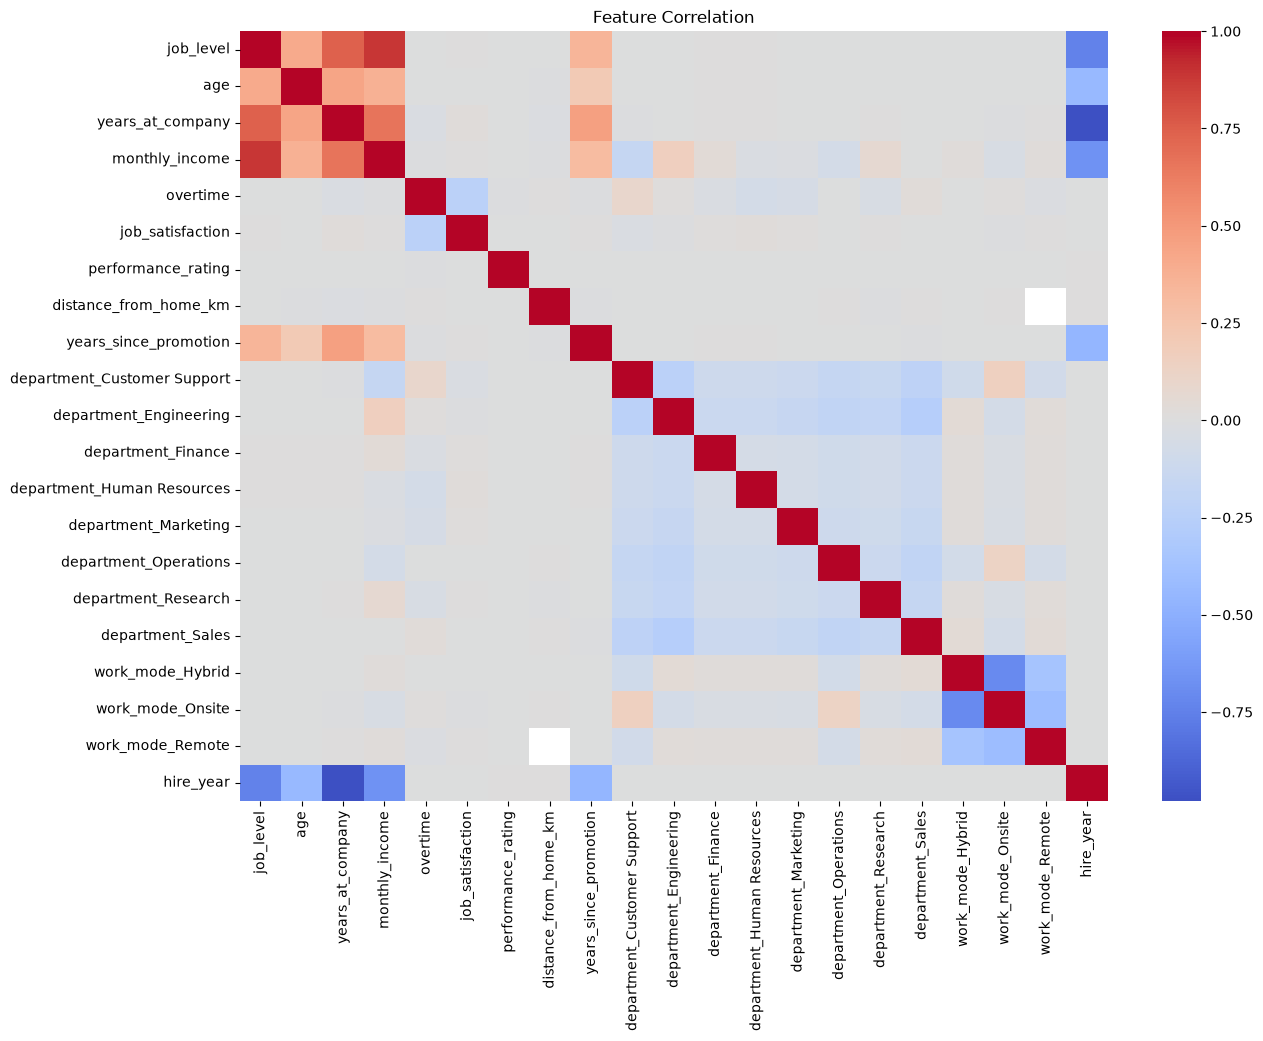

In [6]:
#Correlation analysis

plt.figure(figsize=(14, 10))
sns.heatmap(X.corr(), cmap="coolwarm", center=0)
plt.title("Feature Correlation")
plt.show()

In [7]:
#Feature correlation with attrition

correlation = df.corr(numeric_only=True)["attrition"].drop("attrition")
print(correlation.sort_values(key=abs, ascending=False))

overtime                       0.239769
job_satisfaction              -0.210253
years_at_company              -0.128482
distance_from_home_km          0.093740
department_Customer Support    0.075609
monthly_income                -0.060791
work_mode_Remote              -0.058888
work_mode_Onsite               0.049842
department_Research           -0.047139
age                           -0.042298
department_Sales               0.036491
department_Human Resources    -0.033359
job_level                     -0.032877
department_Finance            -0.028184
performance_rating            -0.027175
hire_year                      0.019758
years_since_promotion         -0.017847
department_Operations         -0.017453
department_Marketing          -0.012659
department_Engineering        -0.010825
work_mode_Hybrid              -0.005262
Name: attrition, dtype: float64


In [8]:
#Create new features

df_feature = df.copy()

valid = (
    (df_feature["years_at_company"] > 0) &
    (df_feature["years_since_promotion"] <= df_feature["years_at_company"])
)

df_feature["promotion_tenure_ratio"] = np.nan
df_feature.loc[valid, "promotion_tenure_ratio"] = (
    df_feature.loc[valid, "years_since_promotion"] /
    df_feature.loc[valid, "years_at_company"]
)

df_feature["overtime_tenure"] = (
    df_feature["overtime"] * df_feature["years_at_company"]
)

df_feature[[
    "years_at_company",
    "years_since_promotion",
    "promotion_tenure_ratio",
    "overtime",
    "overtime_tenure"
]].head()

,years_at_company,years_since_promotion,promotion_tenure_ratio,overtime,overtime_tenure
0,11,10,0.909091,1,11
1,11,1,0.090909,1,11
2,11,0,0.000000,1,11
3,11,0,0.000000,0,0
4,11,0,0.000000,1,11


In [9]:
#Check the new features and missing values

print(df_feature[[
    "promotion_tenure_ratio",
    "overtime_tenure"
]].describe())

print("\\nMissing values:")
print(df_feature.isnull().sum()[df_feature.isnull().sum() > 0])

       promotion_tenure_ratio  overtime_tenure
count            89084.000000    100000.000000
mean                 0.443981         1.358810
std                  0.375861         2.686149
min                  0.000000         0.000000
25%                  0.100000         0.000000
50%                  0.333333         0.000000
75%                  0.833333         1.000000
max                  1.000000        11.000000
\nMissing values:
distance_from_home_km     17225
promotion_tenure_ratio    10916
dtype: int64


In [10]:
#Final checks

print("Final shape:", df_feature.shape)
print("Target unchanged:", df_feature["attrition"].equals(df["attrition"]))
print("Duplicate rows:", df_feature.duplicated().sum())
print("Target distribution:")
print(df_feature["attrition"].value_counts())


Final shape: (100000, 24)
Target unchanged: True
Duplicate rows: 3
Target distribution:
attrition
0    83072
1    16928
Name: count, dtype: int64


In [11]:
df_feature.to_csv(
    "../data/processed/feature_engineered_100k.csv",
    index=False
)

print("Feature-engineered dataset saved successfully!")

Feature-engineered dataset saved successfully!
